### 1. Imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

### 2. File Paths

In [2]:
DATA_DIR = Path("../data/house-prices")

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
DESCRIPTION_PATH = DATA_DIR / "data_description.txt"

### 3. Load Dataset

Κατά την ανάγνωση διαχωρίζουμε την κατηγορία «None» από τις πραγματικές ελλείψεις. Τα «NA» και τα άδεια πεδία θεωρούνται κενά.

In [3]:
train = pd.read_csv(
    TRAIN_PATH, keep_default_na=False, na_values=["NA", ""]
)

test = pd.read_csv(
    TEST_PATH, keep_default_na=False, na_values=["NA", ""]
)
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


### 4. Basic Dataset Exploration

Ξεκινάμε με μια πρώτη εικόνα του dataset, εξετάζοντας τις πρώτες γραμμές,
τους τύπους των μεταβλητών, βασικά στατιστικά στοιχεία και τις στήλες
που περιέχουν missing values.


In [4]:
train.head()
train.info()
train.describe().T
missing_values = train.isnull().sum().sort_values(ascending=False)

missing_values[missing_values > 0]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64

#### 4.1 Missing Values Summary

Δημιουργούμε έναν συνοπτικό πίνακα με το πλήθος και το ποσοστό
των missing values για κάθε μεταβλητή.

Με αυτόν τον τρόπο μπορούμε να δούμε ποιες στήλες χρειάζονται
περισσότερη προσοχή στο preprocessing.

In [5]:
missing_summary = pd.DataFrame({
    "missing_count": train.isnull().sum(),
    "missing_percentage": train.isnull().mean() * 100,
    "dtype": train.dtypes
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_percentage,dtype
PoolQC,1453,99.520548,object
MiscFeature,1406,96.301370,object
Alley,1369,93.767123,object
Fence,1179,80.753425,object
FireplaceQu,690,47.260274,object
LotFrontage,259,17.739726,float64
GarageType,81,5.547945,object
GarageYrBlt,81,5.547945,float64
GarageFinish,81,5.547945,object
GarageQual,81,5.547945,object


#### 4.2 Categorical Missing Values

Εξετάζουμε ξεχωριστά τις κατηγορικές μεταβλητές που περιέχουν
missing values.

Οι συχνότητες των κατηγοριών μας βοηθούν να καταλάβουμε αν ένα
missing value σημαίνει πραγματική έλλειψη πληροφορίας ή απουσία
ενός χαρακτηριστικού, όπως garage, basement ή pool.

In [6]:
categorical_missing = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "MasVnrType",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtFinType1",
    "BsmtFinType2",
    "BsmtExposure",
    "BsmtQual",
    "BsmtCond",
    "Electrical"
]

for col in categorical_missing:
    print(f"\n--- {col} ---")
    print(train[col].value_counts(dropna=False))


--- PoolQC ---
PoolQC
NaN    1453
Gd        3
Ex        2
Fa        2
Name: count, dtype: int64

--- MiscFeature ---
MiscFeature
NaN     1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: count, dtype: int64

--- Alley ---
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

--- Fence ---
Fence
NaN      1179
MnPrv     157
GdPrv      59
GdWo       54
MnWw       11
Name: count, dtype: int64

--- MasVnrType ---
MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
NaN          8
Name: count, dtype: int64

--- FireplaceQu ---
FireplaceQu
NaN    690
Gd     380
TA     313
Fa      33
Ex      24
Po      20
Name: count, dtype: int64

--- GarageType ---
GarageType
Attchd     870
Detchd     387
BuiltIn     88
NaN         81
Basment     19
CarPort      9
2Types       6
Name: count, dtype: int64

--- GarageFinish ---
GarageFinish
Unf    605
RFn    422
Fin    352
NaN     81
Name: count, dtype: int64

--- GarageQual ---
GarageQual
TA     1311
NaN      

#### 4.3 Numerical Missing Values

Εξετάζουμε τις αριθμητικές μεταβλητές που έχουν missing values
και τα βασικά στατιστικά τους.

Αυτό μας βοηθά να επιλέξουμε πιο κατάλληλο τρόπο συμπλήρωσης
αντί να χρησιμοποιήσουμε την ίδια μέθοδο για όλες τις μεταβλητές.

In [7]:
numeric_missing = [
    "LotFrontage",
    "GarageYrBlt",
    "MasVnrArea"
]

for col in numeric_missing:
    print(f"\n--- {col} ---")
    print(train[col].describe())


--- LotFrontage ---
count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64

--- GarageYrBlt ---
count    1379.000000
mean     1978.506164
std        24.689725
min      1900.000000
25%      1961.000000
50%      1980.000000
75%      2002.000000
max      2010.000000
Name: GarageYrBlt, dtype: float64

--- MasVnrArea ---
count    1452.000000
mean      103.685262
std       181.066207
min         0.000000
25%         0.000000
50%         0.000000
75%       166.000000
max      1600.000000
Name: MasVnrArea, dtype: float64


### 5. Missing Values Analysis

Πριν συμπληρώσουμε τις missing τιμές, εξετάζουμε αν ορισμένες από αυτές
συνδέονται με την πραγματική απουσία ενός χαρακτηριστικού.

Για παράδειγμα, ελέγχουμε αν τα missing values του `GarageYrBlt`
εμφανίζονται στα ίδια σπίτια που δεν έχουν garage και αν υπάρχει
αντίστοιχη σχέση μεταξύ `MasVnrType` και `MasVnrArea`.

In [8]:
print("GarageType vs GarageYrBlt")
print(
    pd.crosstab(
        train["GarageType"].isna(),
        train["GarageYrBlt"].isna()
    )
)

print("\nMasVnrType vs MasVnrArea")
print(
    pd.crosstab(
        train["MasVnrType"].isna(),
        train["MasVnrArea"].isna()
    )
)

GarageType vs GarageYrBlt
GarageYrBlt  False  True 
GarageType               
False         1379      0
True             0     81

MasVnrType vs MasVnrArea
MasVnrArea  False  True 
MasVnrType              
False        1452      0
True            0      8


#### 5.1 LotFrontage and Neighborhood

Εξετάζουμε τη διάμεσο του `LotFrontage` ανά `Neighborhood`.

Αν υπάρχουν σημαντικές διαφορές μεταξύ των περιοχών, είναι πιο λογικό
να συμπληρώσουμε τα missing values με βάση τη γειτονιά και όχι με μία
κοινή τιμή για ολόκληρο το dataset.

In [9]:
lot_frontage_by_neighborhood = (
    train.groupby("Neighborhood")["LotFrontage"]
    .median()
    .sort_values()
)

lot_frontage_by_neighborhood

Neighborhood
BrDale     21.0
MeadowV    21.0
Blueste    24.0
NPkVill    24.0
Blmngtn    43.0
BrkSide    52.0
SWISU      60.0
IDOTRR     60.0
OldTown    60.0
StoneBr    61.5
Gilbert    65.0
Edwards    65.5
SawyerW    66.5
Veenker    68.0
CollgCr    70.0
Sawyer     71.0
Mitchel    73.0
NAmes      73.0
Somerst    73.5
Crawfor    74.0
NWAmes     80.0
ClearCr    80.0
Timber     85.0
NridgHt    88.5
NoRidge    91.0
Name: LotFrontage, dtype: float64

Βλέπουμε μερικές πραγματικές παρατηρήσεις του `Neighborhood`
και του `LotFrontage`

In [10]:
train[["Neighborhood", "LotFrontage"]].head(20)

,Neighborhood,LotFrontage
0,CollgCr,65.0
1,Veenker,80.0
2,CollgCr,68.0
3,Crawfor,60.0
4,NoRidge,84.0
5,Mitchel,85.0
6,Somerst,75.0
7,NWAmes,NaN
8,OldTown,51.0
9,BrkSide,50.0


### 6.1 Create Clean Copies

Δημιουργούμε αντίγραφα των αρχικών datasets ώστε οι αλλαγές
του preprocessing να μην επηρεάσουν τα raw δεδομένα.

Επίσης μετατρέπουμε το `MSSubClass` σε categorical μεταβλητή,
καθώς οι αριθμοί του λειτουργούν ως κωδικοί κατηγορίας κατοικίας
και όχι ως πραγματικές αριθμητικές μετρήσεις.

In [11]:
train_clean = train.copy()
test_clean = test.copy()

#Το MSSubClass περιεχει κωδικους κατηγοριων κατοικιας
train_clean["MSSubClass"] = train_clean["MSSubClass"].astype(str)
test_clean["MSSubClass"] = test_clean["MSSubClass"].astype(str)

### 6.2 Categorical Missing Values

Διαχωρίζουμε την απουσία ενός χαρακτηριστικού από την άγνωστη πληροφορία.

Όταν από τις υπόλοιπες μεταβλητές φαίνεται ότι μια εγκατάσταση υπάρχει,
αλλά λείπει η περιγραφή της, χρησιμοποιούμε την τιμή `Unknown`.
Όταν δεν υπάρχει ένδειξη ότι η εγκατάσταση υπάρχει, χρησιμοποιούμε `None`.

In [12]:
basement_cols = [
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2"
]

garage_cols = [
    "GarageType", "GarageFinish", "GarageQual", "GarageCond"
]

for df in [train_clean, test_clean]:

    has_basement = (     # Ελεγχουμε αν υπαρχουν στοιχεια οτι υπαρχει υπογειο η γκαραζ
        df["TotalBsmtSF"].gt(0)
        | df[basement_cols].notna().any(axis=1)
    )

    has_garage = (
        df["GarageArea"].gt(0)
        | df["GarageCars"].gt(0)
        | df[garage_cols].notna().any(axis=1)
    )

    for col in basement_cols:  # εαν υπαρχει υπογειο αλλα η πληροφορια ειναι αγνωστη
        df.loc[df[col].isna() & has_basement, col] = "Unknown"
        df[col] = df[col].fillna("None")

    for col in garage_cols:
        df.loc[df[col].isna() & has_garage, col] = "Unknown"
        df[col] = df[col].fillna("None")

    for col in ["Alley", "Fence", "MiscFeature"]:
        df[col] = df[col].fillna("None")

    for col, amount in [
        ("PoolQC", "PoolArea"),
        ("FireplaceQu", "Fireplaces"),
        ("MasVnrType", "MasVnrArea")
    ]:
        df.loc[df[col].isna() & df[amount].eq(0), col] = "None"
        df[col] = df[col].fillna("Unknown")

### 6.3 Numerical Features: Structural Missing Values

Για numerical χαρακτηριστικά που σχετίζονται με basement ή garage,
η τιμή 0 χρησιμοποιείται όταν η αντίστοιχη εγκατάσταση δεν υπάρχει.

Σε περιπτώσεις όπου η εγκατάσταση υπάρχει αλλά η αριθμητική πληροφορία
λείπει, χρησιμοποιούμε τη διάμεσο από το training dataset.

In [13]:
# Αριθμητικα χαρακτηριστικα υπογειου και γκαραζ
basement_numbers = [
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
    "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"
]

garage_numbers = ["GarageArea", "GarageCars"]

for df in [train_clean, test_clean]:

    
    for col in basement_numbers: # Οταν δεν υπαρχει υπογειο, συμπληρωνουμε τα κενα με 0
        df.loc[df["BsmtQual"].eq("None"), col] = (
            df.loc[df["BsmtQual"].eq("None"), col].fillna(0)
        )

    
    for col in garage_numbers: # Οταν δεν υπαρχει γκαραζ, συμπληρωνουμε τα κενα με 0
        df.loc[df["GarageType"].eq("None"), col] = (
            df.loc[df["GarageType"].eq("None"), col].fillna(0)
        )

    # Οταν δεν υπαρχει επενδυση τοιχοποιιας, συμπληρωνουμε την κενη επιφανεια με 0
    df.loc[df["MasVnrType"].eq("None"), "MasVnrArea"] = (
        df.loc[df["MasVnrType"].eq("None"), "MasVnrArea"].fillna(0)
    )

    # Εντοπιζουμε μη εγκυρα ετη κατασκευης γκαραζ
    invalid_year = (
        df["GarageYrBlt"].gt(df["YrSold"])
        | df["GarageYrBlt"].le(0)
    )
    df.loc[invalid_year, "GarageYrBlt"] = np.nan

for col in basement_numbers + garage_numbers + ["MasVnrArea", "GarageYrBlt"]:# Συμπληρωνουμε τα υπολοιπα κενα με διαμεσους απο το train

    if col in ["GarageArea", "GarageCars", "MasVnrArea"]:     # Για αυτα τα χαρακτηριστικα χρησιμοποιουμε μονο τις θετικες τιμες

        median_value = train_clean.loc[train_clean[col].gt(0), col].median()
    else:
        median_value = train_clean[col].median()

    # Εφαρμοζουμε την ιδια διαμεσο στο train και στο test
    train_clean[col] = train_clean[col].fillna(median_value)
    test_clean[col] = test_clean[col].fillna(median_value)

# Το ετος κατασκευης γκαραζ δεν πρεπει να ξεπερνα το ετος πωλησης
for df in [train_clean, test_clean]:
    df["GarageYrBlt"] = df["GarageYrBlt"].clip(upper=df["YrSold"])

### 6.4 LotFrontage Imputation by Neighborhood

Για το `LotFrontage` χρησιμοποιούμε τη διάμεσο της αντίστοιχης γειτονιάς.

Η επιλογή αυτή βασίζεται στο ότι η πρόσοψη των οικοπέδων διαφέρει
μεταξύ των `Neighborhoods`, ενώ η διάμεσος επηρεάζεται λιγότερο
από πολύ μεγάλες ή πολύ μικρές τιμές.

In [14]:
frontage_by_neighborhood = train_clean.groupby( #υπολογιζουμε την διαμεσο της προσοψης ανα γειτονια απο το train
    "Neighborhood"
)["LotFrontage"].median()

frontage_median = train_clean["LotFrontage"].median()

for df in [train_clean, test_clean]: #κανουμε το ιδιο για την συμπληρωση σε train και τεστ
    df["LotFrontage"] = (
        df["LotFrontage"]
        .fillna(df["Neighborhood"].map(frontage_by_neighborhood))
        .fillna(frontage_median)
    )

#### 6.4.1 Validation of LotFrontage Imputation

Συγκρίνουμε τα βασικά στατιστικά και την κατανομή του `LotFrontage`
πριν και μετά το imputation.

Ο έλεγχος αυτός γίνεται για να βεβαιωθούμε ότι η συμπλήρωση των
missing values δεν άλλαξε υπερβολικά τη μορφή της μεταβλητής.

,Before,After
count,1201.00,1460.00
mean,70.05,70.20
std,24.28,22.43
min,21.00,21.00
25%,59.00,60.00
50%,69.00,70.00
75%,80.00,80.00
max,313.00,313.00


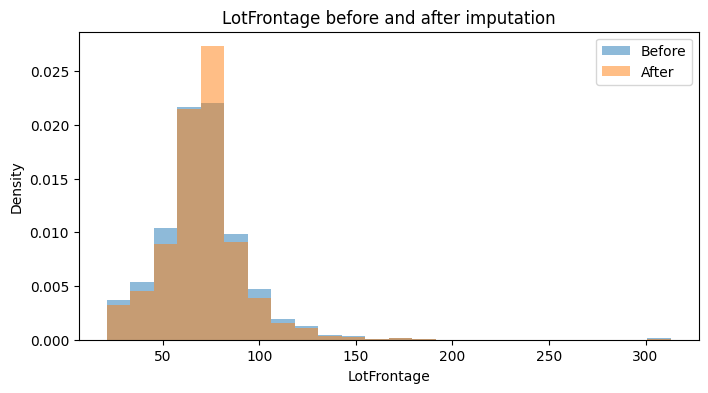

In [15]:
#συγκρισει στατιστκων πριν και μετα τη συμπληρωση
comparison = pd.DataFrame({
    "Before": train["LotFrontage"].describe(),
    "After": train_clean["LotFrontage"].describe()
})

display(comparison.round(2))

bins = np.linspace(
    train_clean["LotFrontage"].min(),
    train_clean["LotFrontage"].max(),
    25
)

plt.figure(figsize=(8, 4))
plt.hist(
    train["LotFrontage"].dropna(),
    bins=bins, density=True, alpha=0.5, label="Before"
)
plt.hist(
    train_clean["LotFrontage"],
    bins=bins, density=True, alpha=0.5, label="After"
)
plt.xlabel("LotFrontage")
plt.ylabel("Density")
plt.title("LotFrontage before and after imputation")
plt.legend()
plt.show()

### 6.5 Electrical Imputation

Η μεταβλητή `Electrical` έχει πολύ μικρό αριθμό missing values.

Για αυτό χρησιμοποιούμε τη συχνότερη κατηγορία του training dataset,
ώστε να γίνει μια απλή και λογική συμπλήρωση.

In [16]:
electrical_mode = train_clean["Electrical"].mode()[0]

train_clean["Electrical"] = train_clean["Electrical"].fillna(electrical_mode)
test_clean["Electrical"] = test_clean["Electrical"].fillna(electrical_mode)

### 6.5b Other Categorical Missing Values

Για τις υπόλοιπες κατηγορικές μεταβλητές με λίγες missing τιμές,
χρησιμοποιούμε τη συχνότερη κατηγορία της κάθε στήλης στο train.

Η ίδια τιμή εφαρμόζεται και στο test ώστε να χρησιμοποιείται
ο ίδιος κανόνας preprocessing και στα δύο datasets.

In [17]:
categorical_to_fill = [
    "MSZoning", "Utilities", "Exterior1st", "Exterior2nd",
    "KitchenQual", "Functional", "SaleType"
]

for col in categorical_to_fill:
    most_common = train_clean[col].mode()[0]

    train_clean[col] = train_clean[col].fillna(most_common)
    test_clean[col] = test_clean[col].fillna(most_common)

### 6.6 Missing Values Validation

Μετά την εφαρμογή των παραπάνω κανόνων, ελέγχουμε ξανά train και test
για να επιβεβαιώσουμε ότι δεν έχουν απομείνει missing values
που δεν έχουμε αντιμετωπίσει.

In [18]:
remaining_missing_train = (
    train_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

remaining_missing_train[remaining_missing_train > 0]

Series([], dtype: int64)

In [19]:
remaining_missing_test = (
    test_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

remaining_missing_test[remaining_missing_test > 0]

Series([], dtype: int64)

### 7. Outlier Analysis

Σε αυτή την ενότητα εξετάζουμε πιθανές ακραίες τιμές στις
αριθμητικές μεταβλητές.

Η ύπαρξη μιας ακραίας τιμής δεν σημαίνει απαραίτητα ότι είναι
λανθασμένη. Για αυτό εξετάζουμε τις κατανομές και τα box plots
πριν αποφασίσουμε αν χρειάζεται να αφαιρεθούν παρατηρήσεις.

### 7.1 Box Plots

Χρησιμοποιούμε box plots για όλες τις numerical μεταβλητές
ώστε να εντοπίσουμε πιθανές ακραίες τιμές.

Τα διαγράμματα αποθηκεύονται και σε PDF ώστε να μπορούν να
χρησιμοποιηθούν αργότερα στην αναφορά.

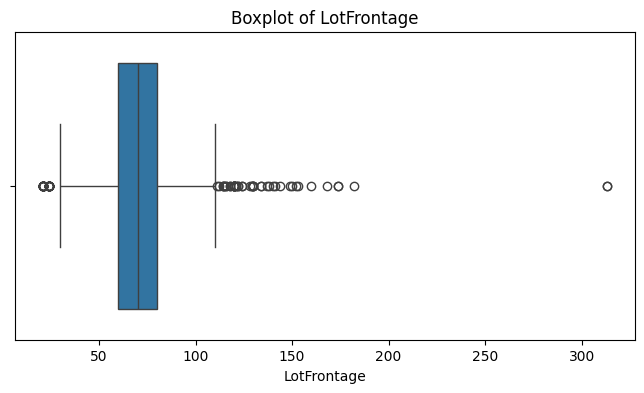

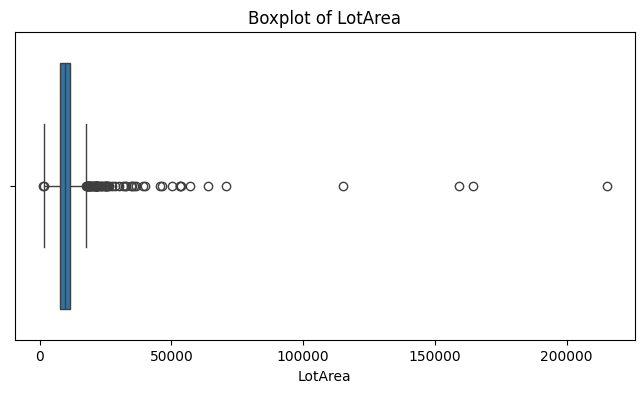

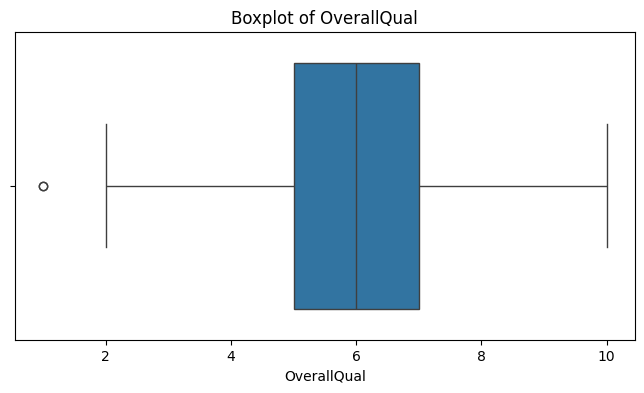

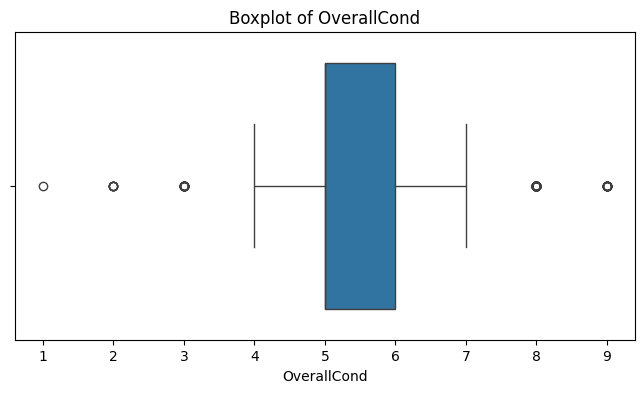

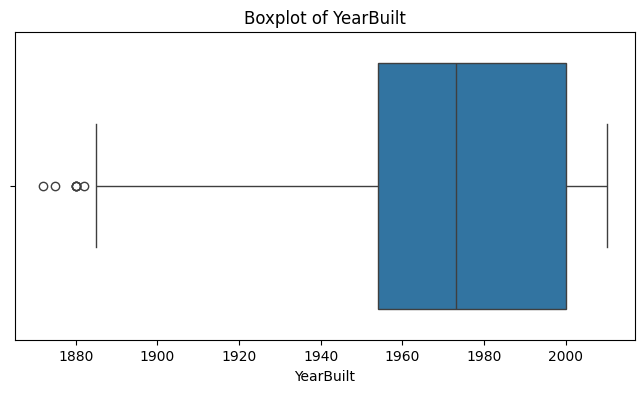

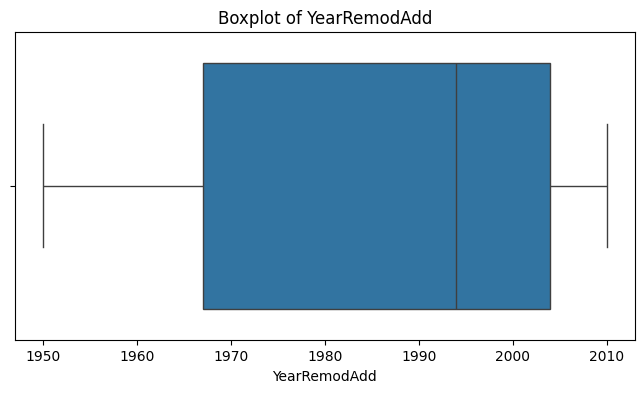

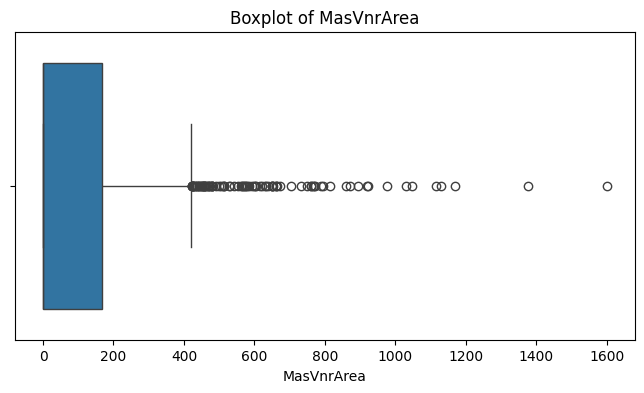

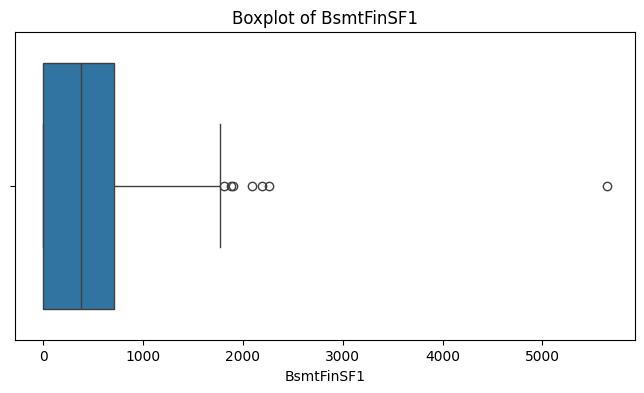

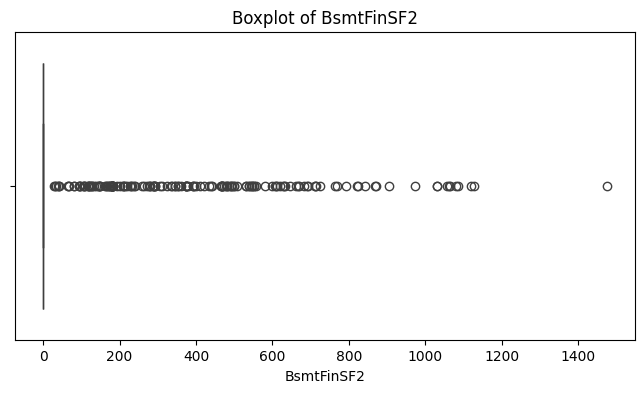

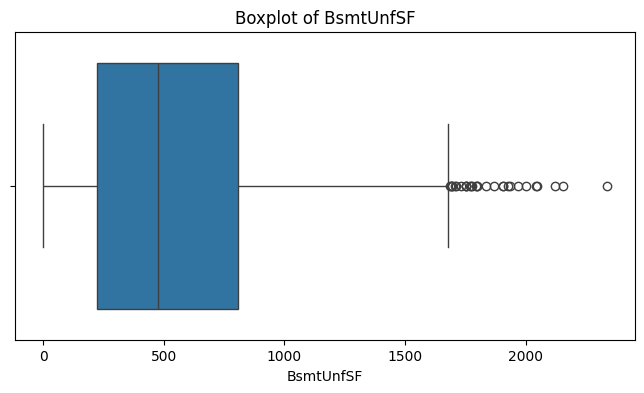

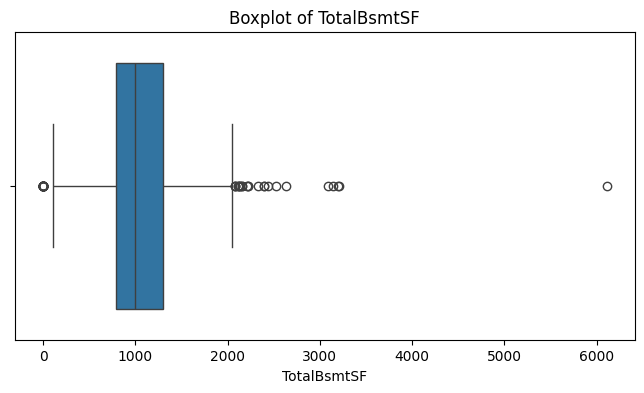

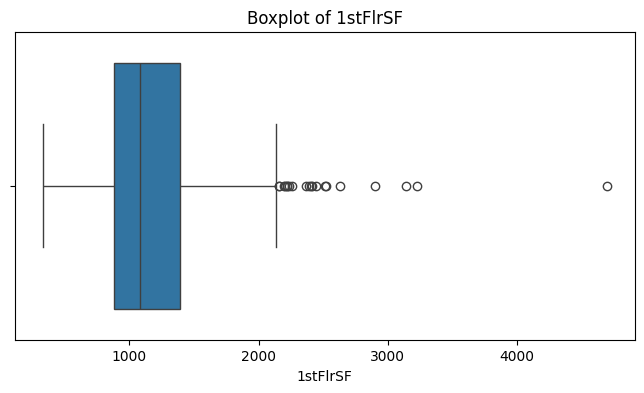

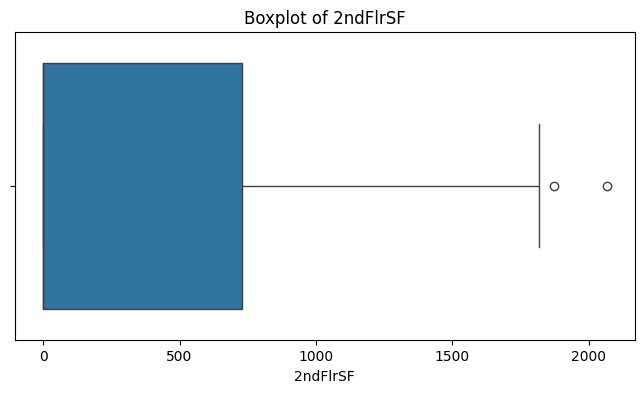

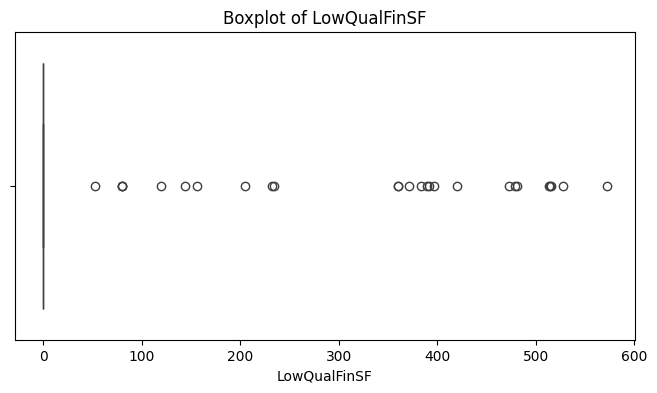

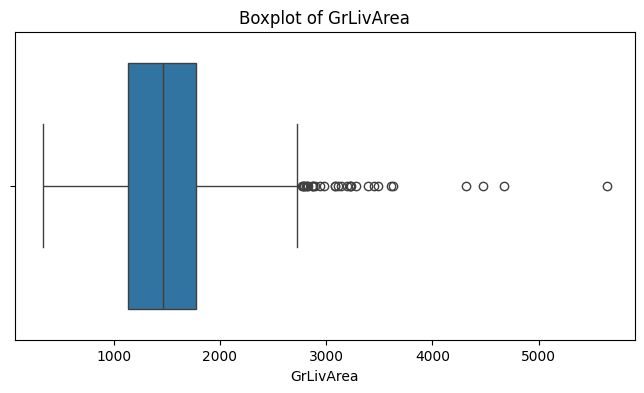

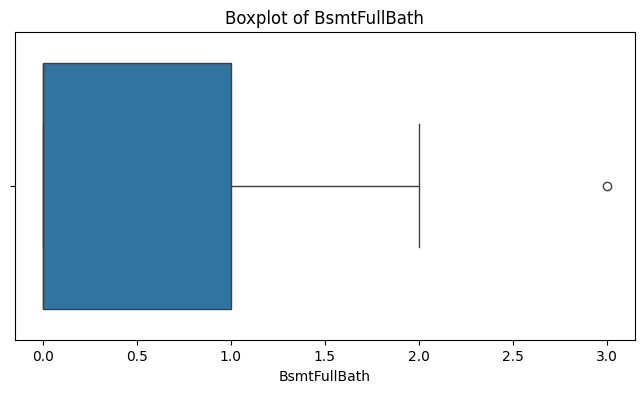

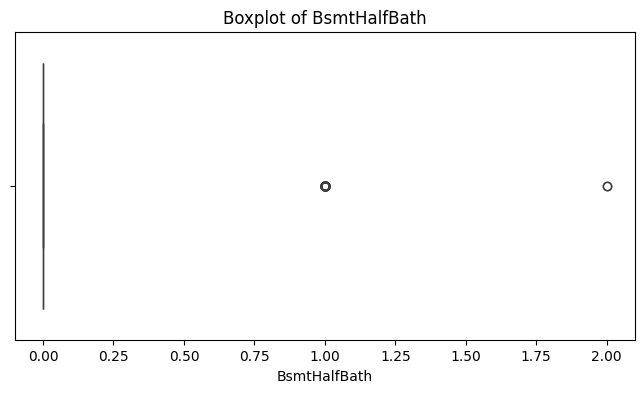

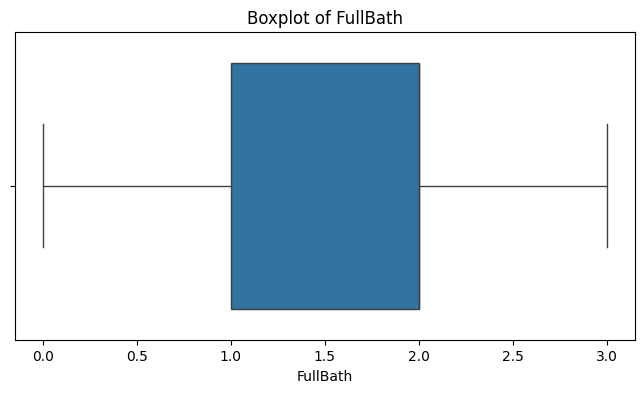

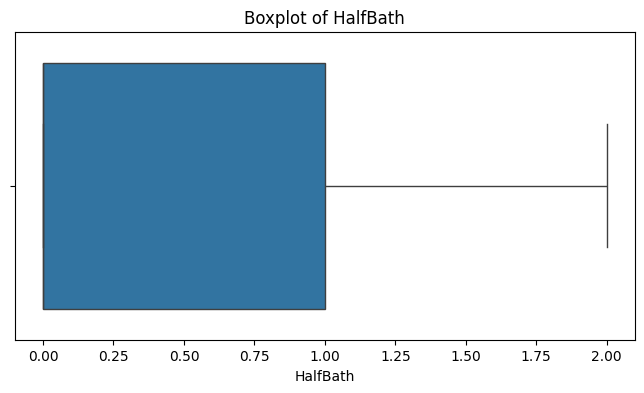

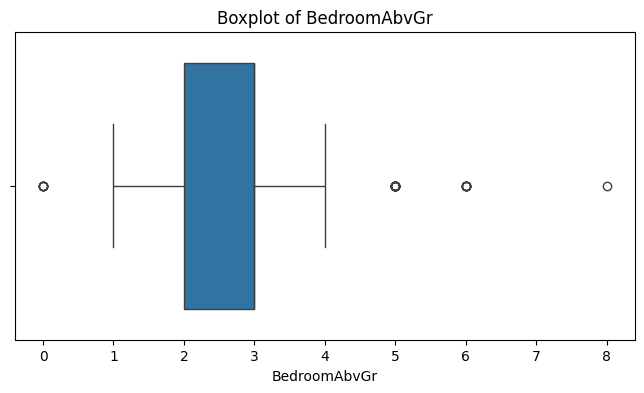

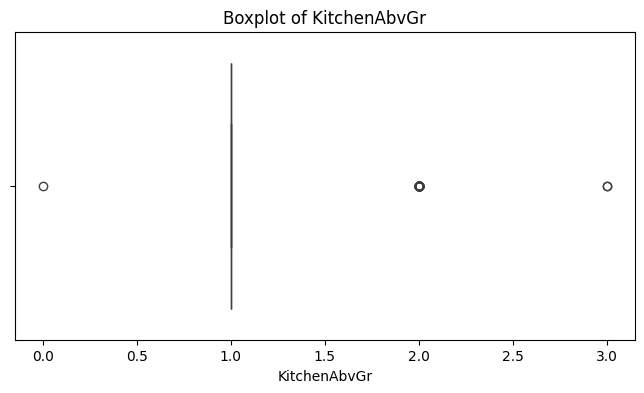

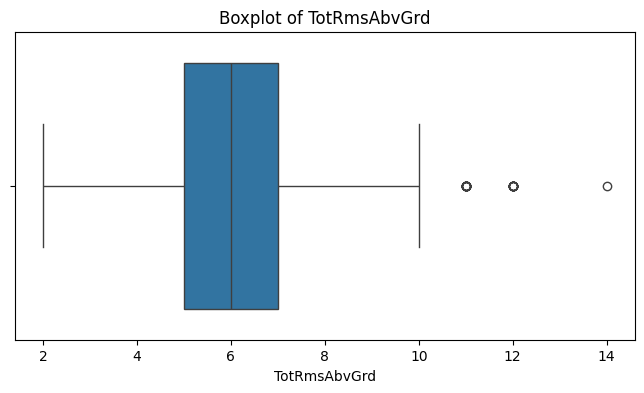

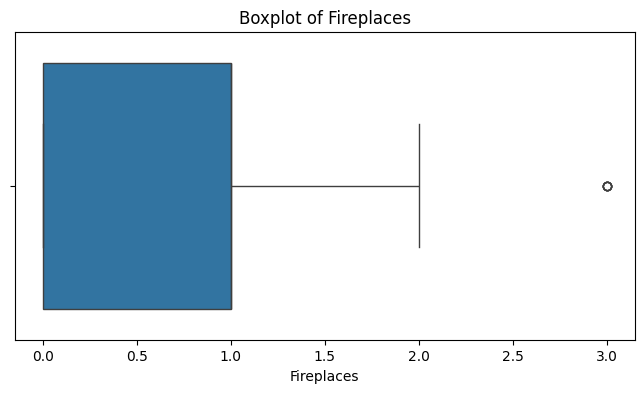

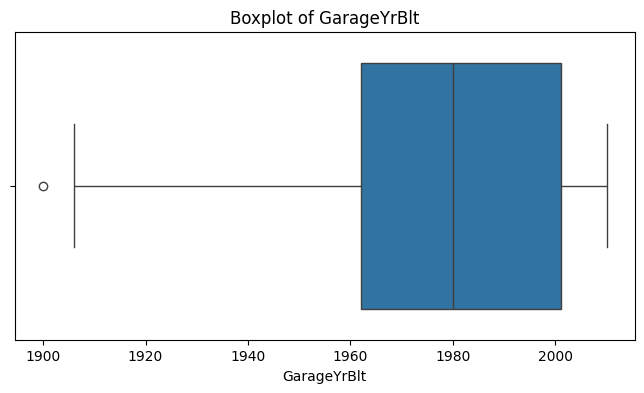

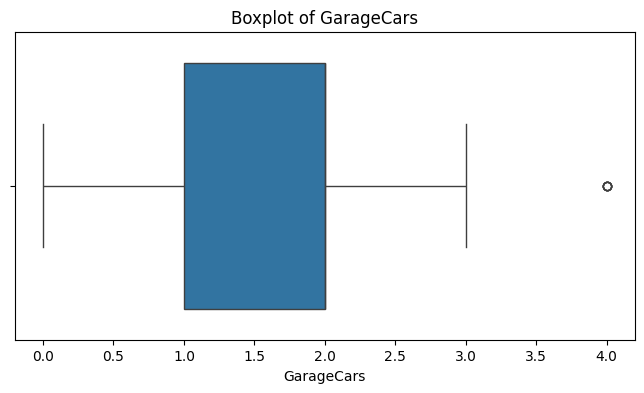

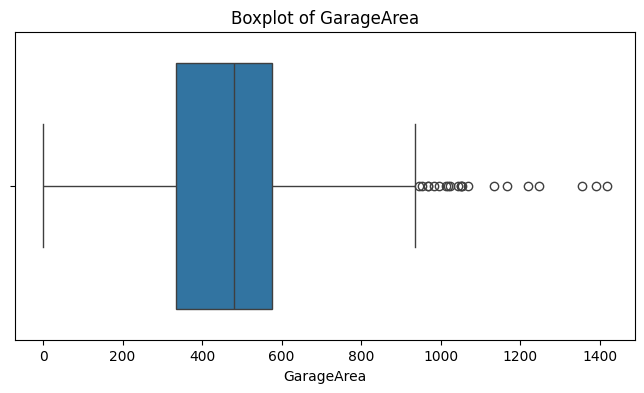

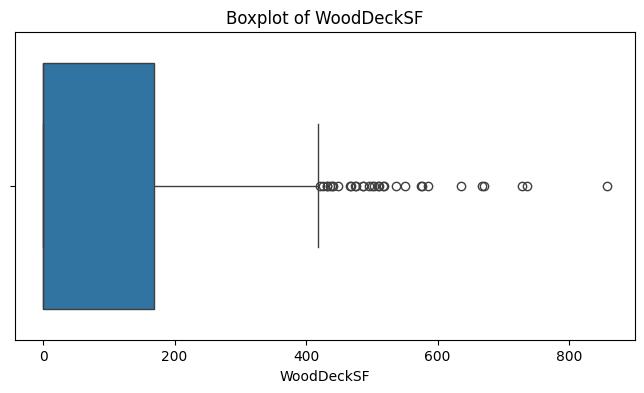

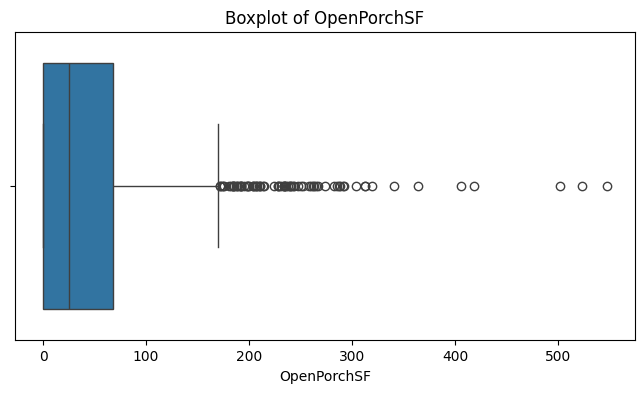

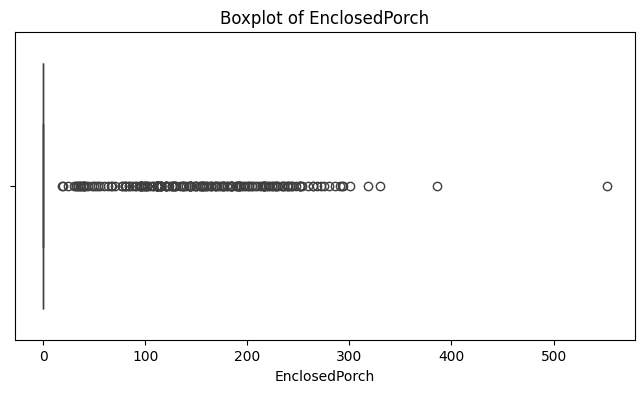

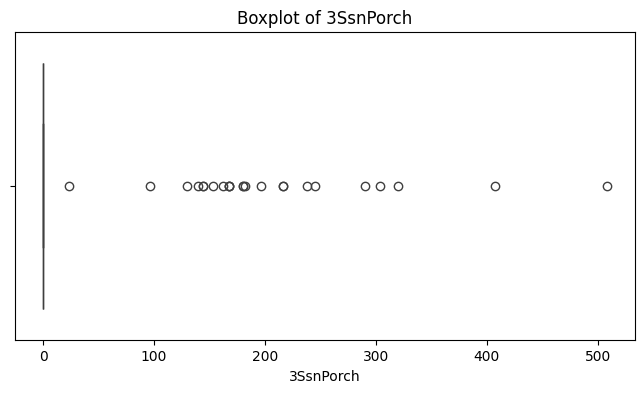

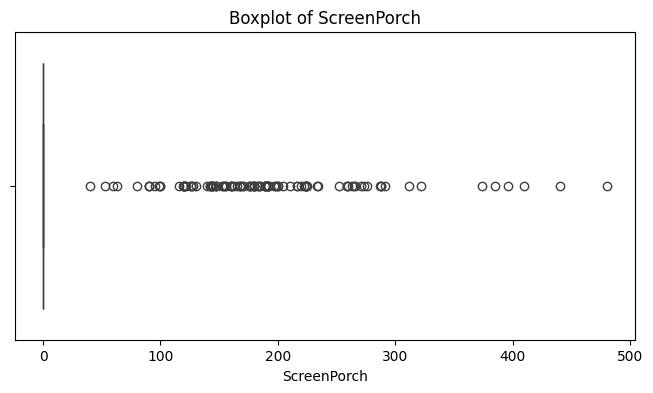

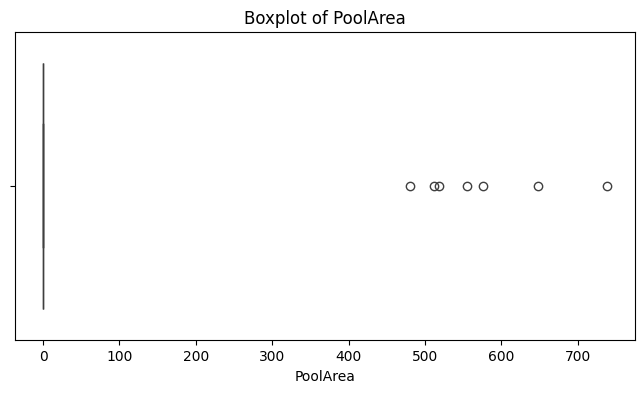

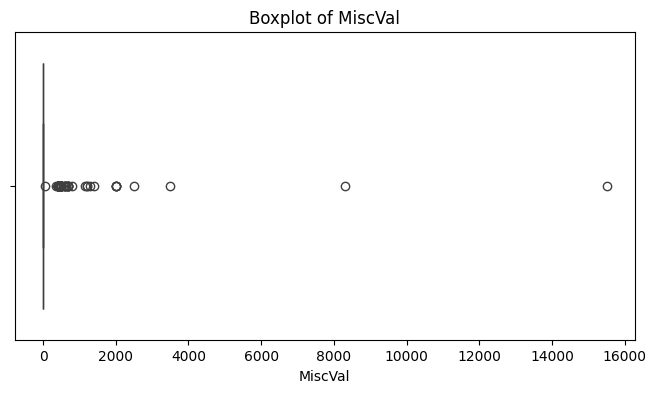

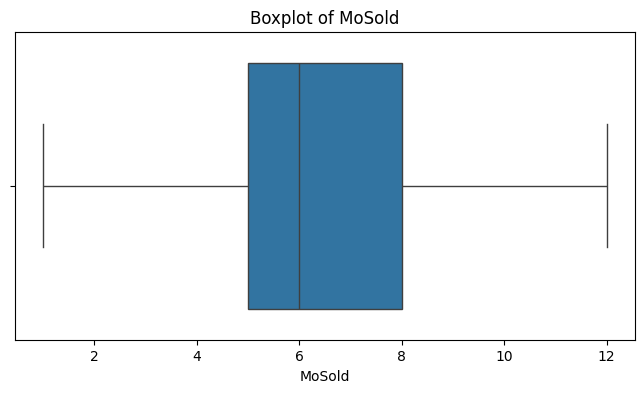

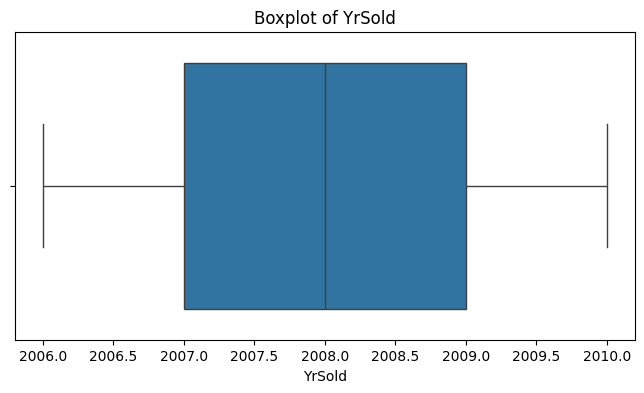

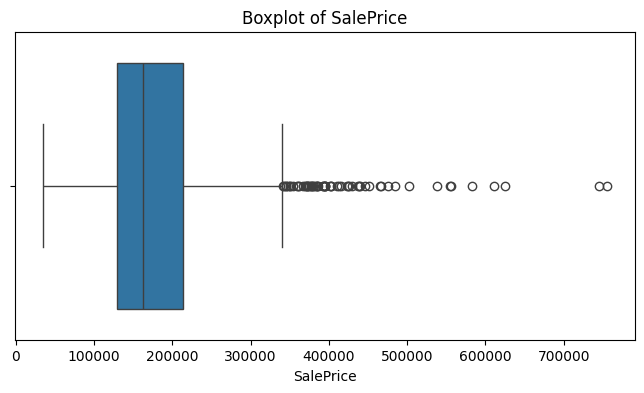

In [20]:
from matplotlib.backends.backend_pdf import PdfPages
numeric_features = train_clean.select_dtypes(include=["number"]).columns.drop("Id", errors = "ignore") #κραταει τα ονοματα των αριθμητικων στηλων ωστε να χρησιμοποιηθουν στα γραφηματα

Path("../results").mkdir(parents=True, exist_ok=True)

with PdfPages("../results/numerical_boxplots.pdf") as pdf:

    for col in numeric_features:
        plt.figure(figsize=(8, 4))

        sns.boxplot(x=train_clean[col])

        plt.title(f"Boxplot of {col}")
        plt.xlabel(col)

        pdf.savefig()
        plt.show()
        plt.close()

### 7.2 IQR Outlier Analysis

Για την πιο συστηματική ανάλυση των πιθανών outliers χρησιμοποιούμε
τον κανόνα του Interquartile Range (IQR).

Μια παρατήρηση θεωρείται πιθανό outlier όταν βρίσκεται κάτω από
το Q1 - 1.5 × IQR ή πάνω από το Q3 + 1.5 × IQR.

Ο έλεγχος εφαρμόζεται στις numerical μεταβλητές του dataset.

In [21]:
outlier_summary = []# Λιστα για την αποθηκευση των αποτελεσματων ανα χαρακτηριστικο

for col in numeric_features:
    # Υπολογιζουμε το πρωτο και το τριτο τεταρτημοριο
    Q1 = train_clean[col].quantile(0.25)
    Q3 = train_clean[col].quantile(0.75)

    IQR = Q3 - Q1 # Υπολογιζουμε το ενδοτεταρτημοριακο ευρος

    # Οριζουμε τα ορια εντοπισμου ακραιων τιμων
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Μετραμε τις τιμες που βρισκονται εκτος των οριων
    outliers = (
        (train_clean[col] < lower) |
        (train_clean[col] > upper)
    ).sum()

    outlier_percentage = outliers / len(train_clean) * 100     # Υπολογιζουμε το ποσοστο τους


    # Αποθηκευουμε το χαρακτηριστικο, το πληθος και το ποσοστο
    outlier_summary.append([
        col,
        outliers,
        outlier_percentage
    ])

# Μετατρεπουμε τα αποτελεσματα σε πινακα
outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=[
        "Feature",
        "Outlier Count",
        "Outlier Percentage"
    ]
)

outlier_summary.sort_values(
    "Outlier Count",
    ascending=False
)

,Feature,Outlier Count,Outlier Percentage
28,EnclosedPorch,208,14.246575
8,BsmtFinSF2,167,11.438356
3,OverallCond,125,8.561644
30,ScreenPorch,116,7.945205
0,LotFrontage,93,6.369863
6,MasVnrArea,93,6.369863
16,BsmtHalfBath,82,5.616438
27,OpenPorchSF,77,5.273973
1,LotArea,69,4.726027
20,KitchenAbvGr,68,4.657534


Ο έλεγχος με τον κανόνα του IQR εντόπισε πιθανές ακραίες τιμές
σε αρκετές numerical μεταβλητές.

Ωστόσο, οι ακραίες τιμές δεν θεωρούνται απαραίτητα λανθασμένες.
Στο συγκεκριμένο dataset πολλές από αυτές μπορούν να αντιστοιχούν
σε πραγματικά χαρακτηριστικά των κατοικιών, όπως πολύ μεγάλη
επιφάνεια, οικόπεδο ή υψηλή τιμή πώλησης.

Επιπλέον, σε ορισμένες μεταβλητές υπάρχουν πολλές μηδενικές τιμές
και λίγες μη μηδενικές παρατηρήσεις, γεγονός που μπορεί να οδηγεί
τον κανόνα του IQR στον χαρακτηρισμό ορισμένων πραγματικών τιμών
ως πιθανών outliers.

Για τον λόγο αυτό δεν αφαιρούμε τις παρατηρήσεις που χαρακτηρίστηκαν
ως outliers μόνο από τον κανόνα του IQR. Οι τιμές διατηρούνται ώστε
να μην χαθούν πιθανώς χρήσιμες πληροφορίες από το dataset.



### 8. Feature Distribution Analysis

Εξετάζουμε τις κατανομές των numerical μεταβλητών χρησιμοποιώντας
ιστογράμματα.

Η ανάλυση αυτή βοηθά να εντοπίσουμε μεταβλητές με έντονη ασυμμετρία,
μεγάλη διακύμανση ή ιδιαίτερα ακραίες κατανομές, ώστε να επιλέξουμε
κατάλληλη μέθοδο μετασχηματισμού ή scaling.

Τα ιστογράμματα αποθηκεύονται επίσης σε PDF ώστε να υπάρχει
συγκεντρωμένη οπτική εικόνα των numerical μεταβλητών.

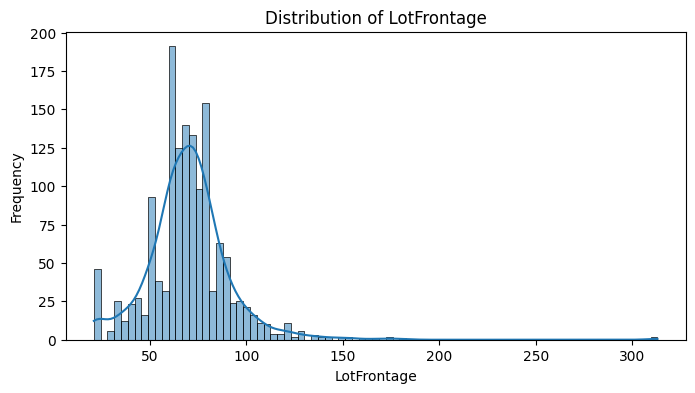

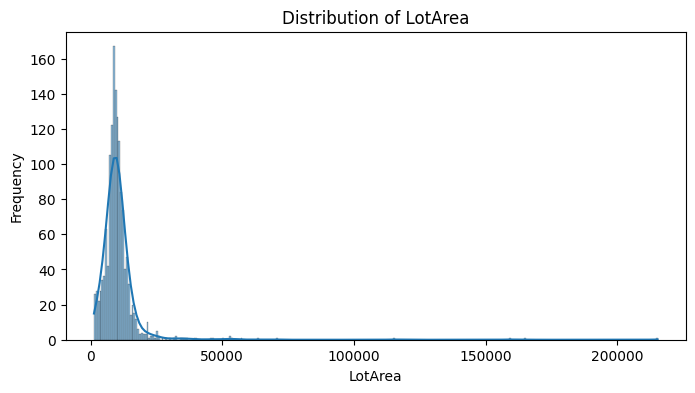

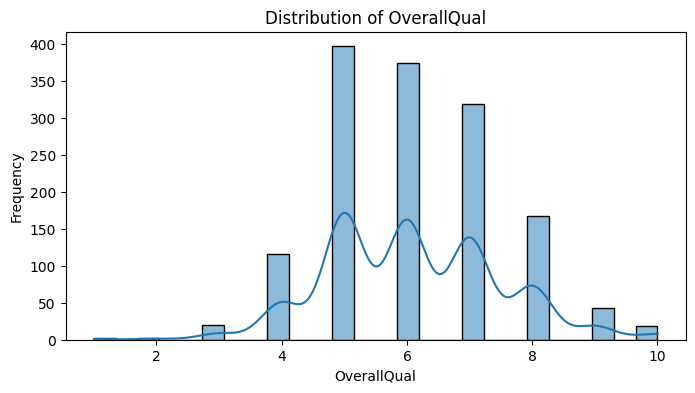

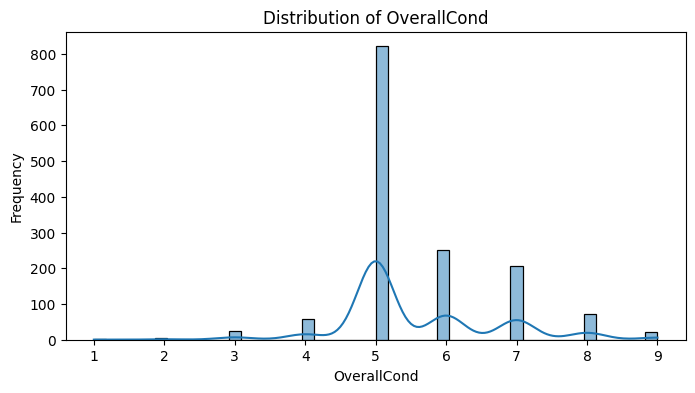

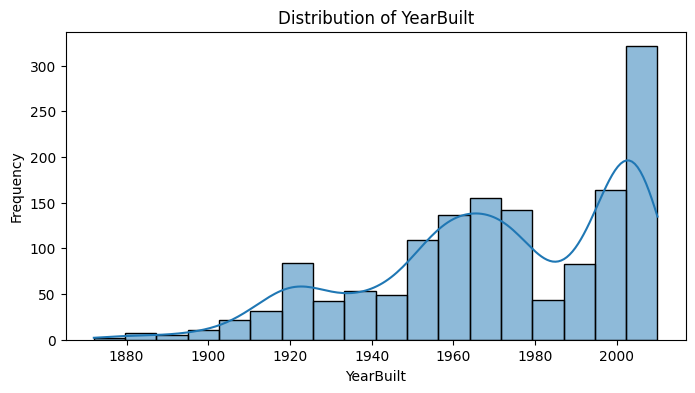

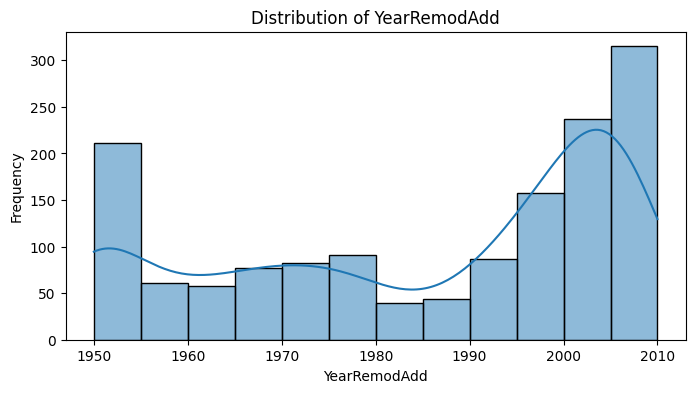

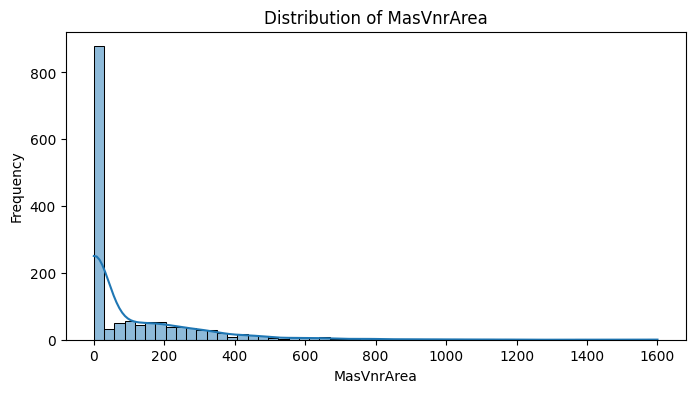

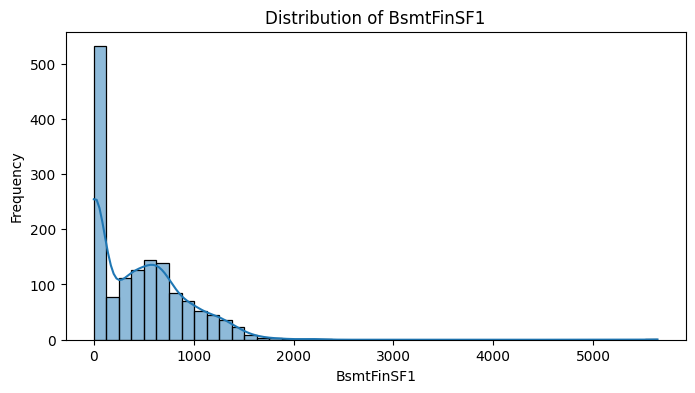

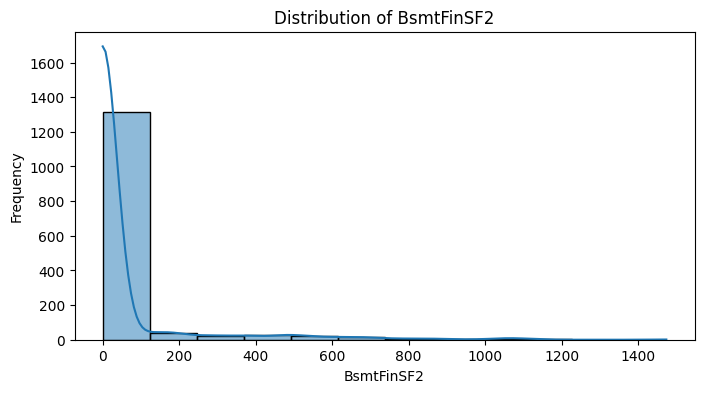

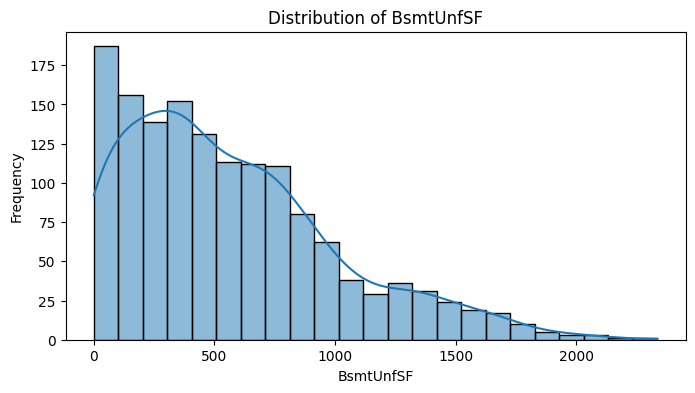

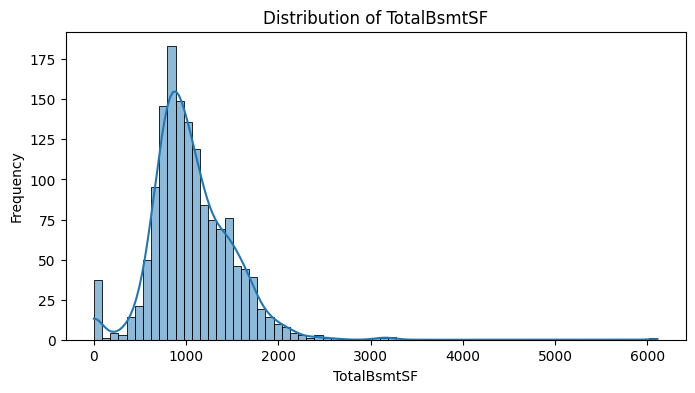

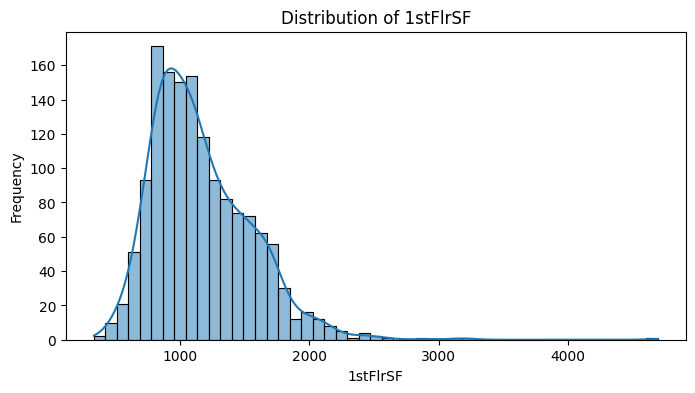

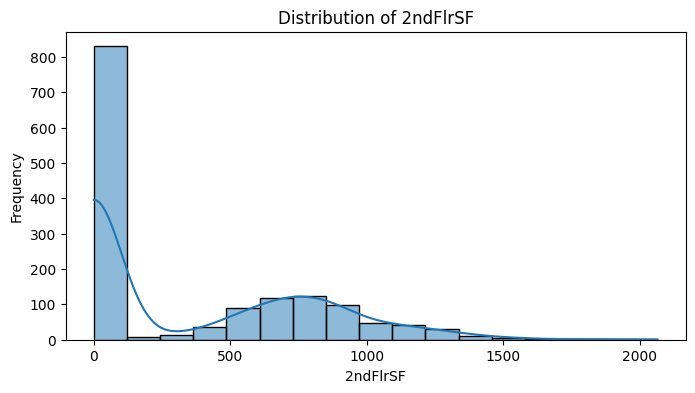

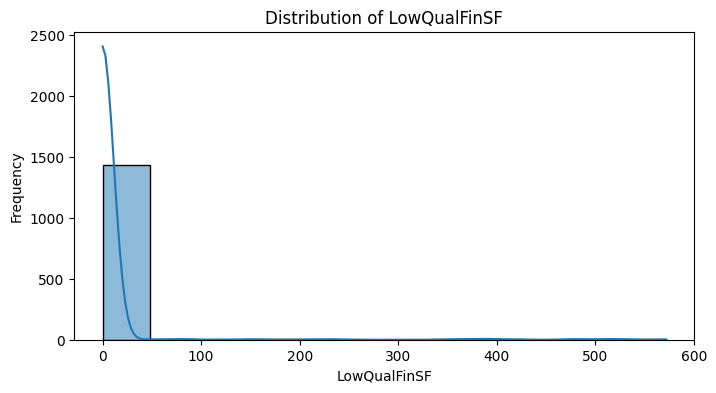

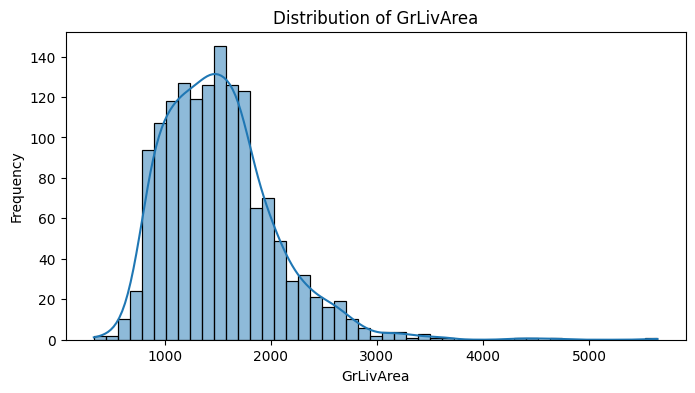

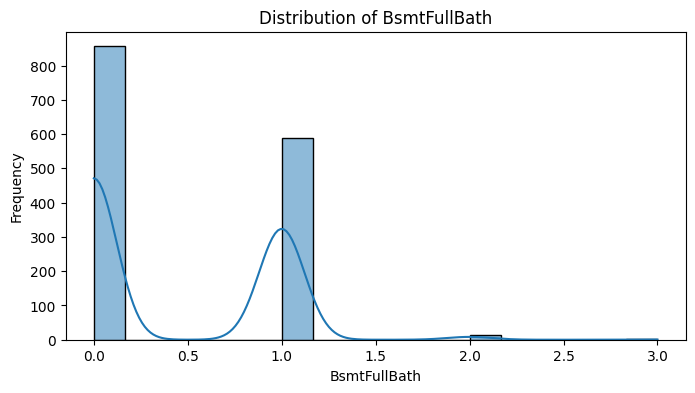

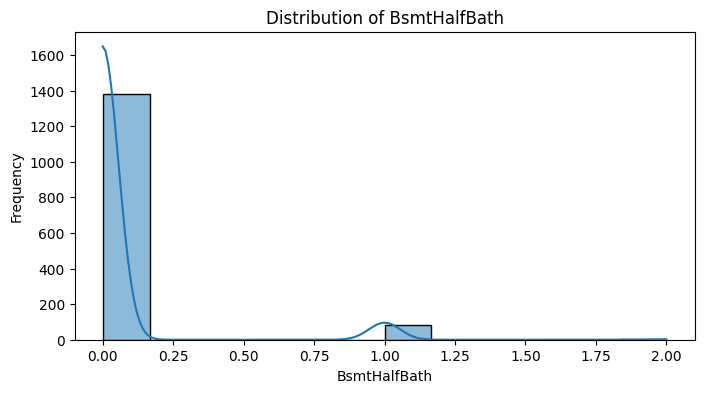

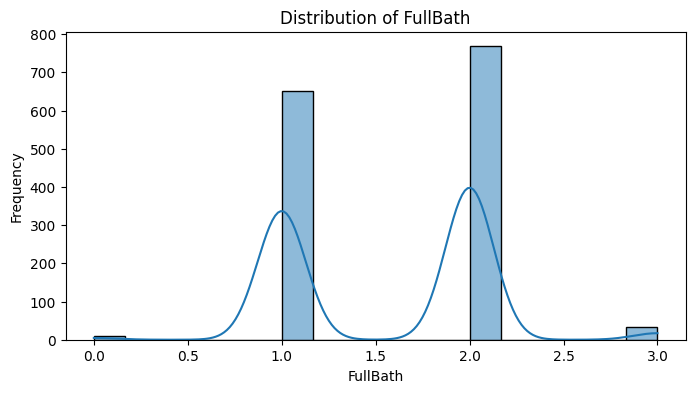

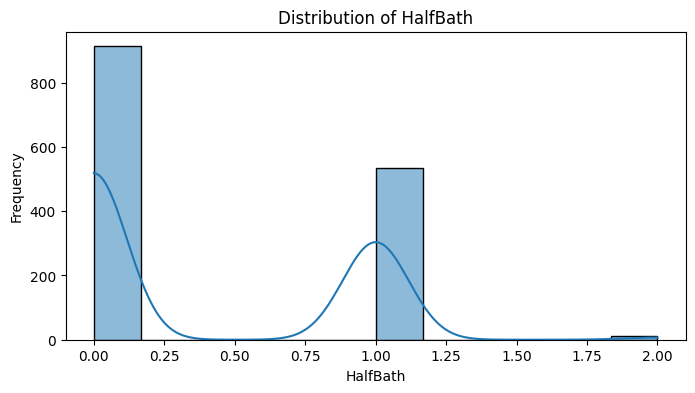

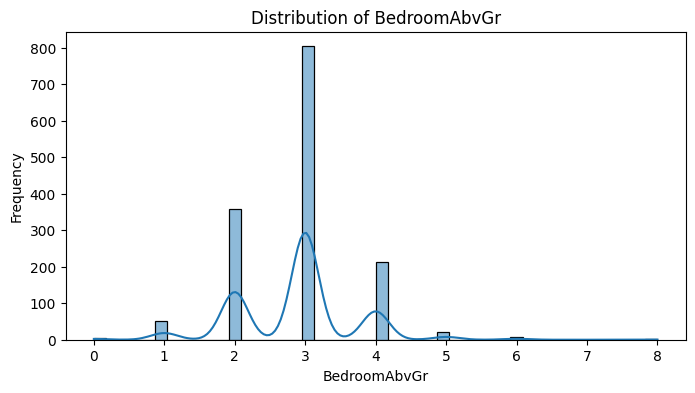

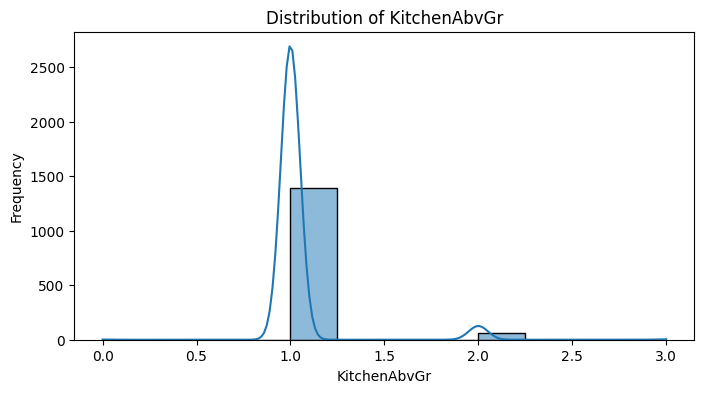

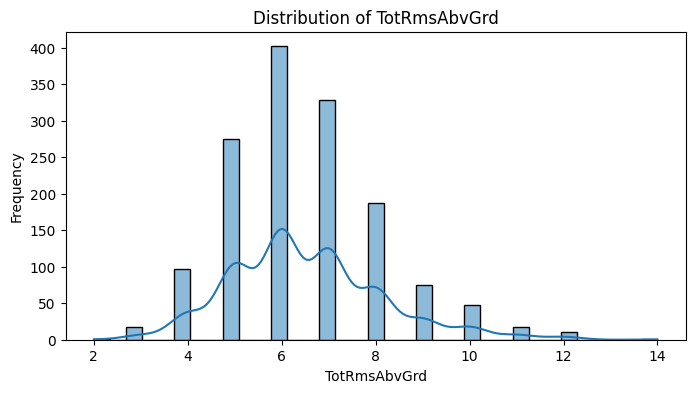

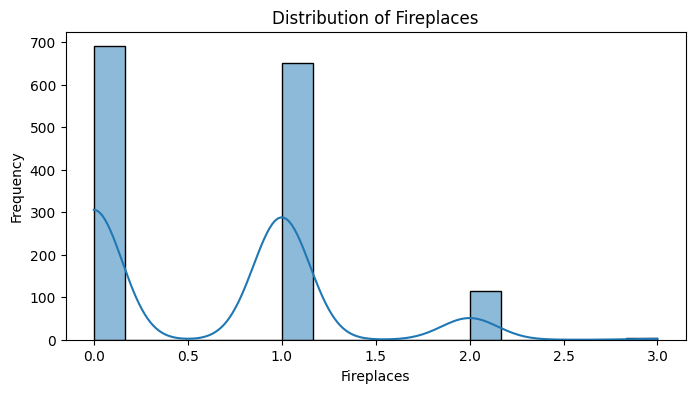

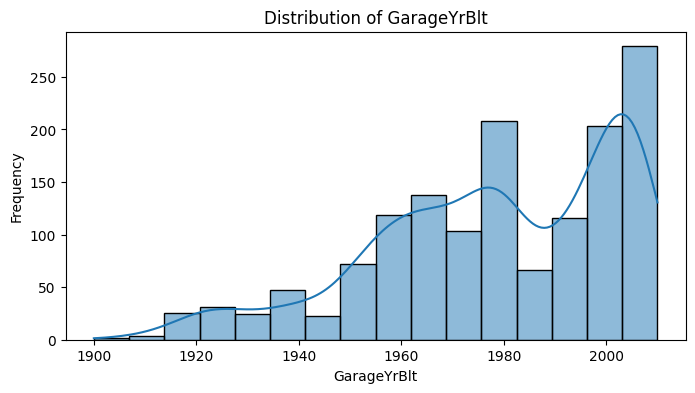

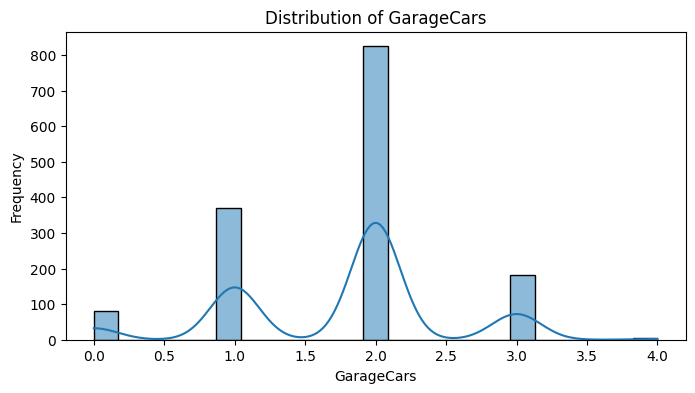

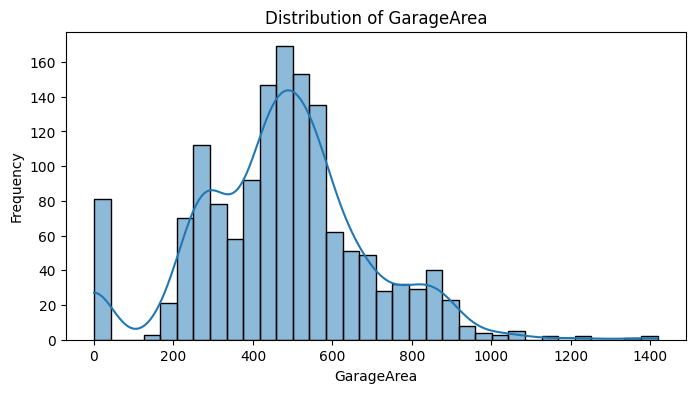

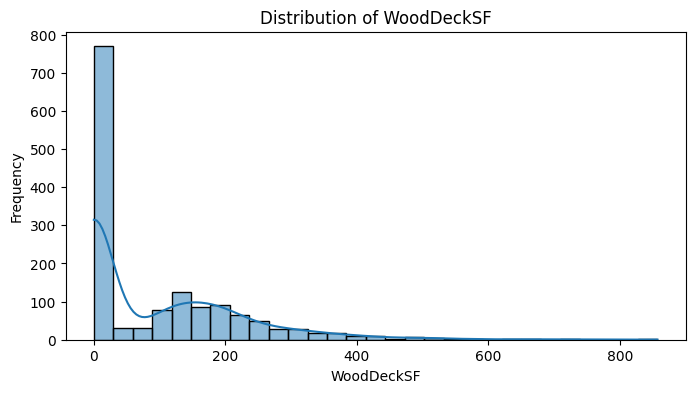

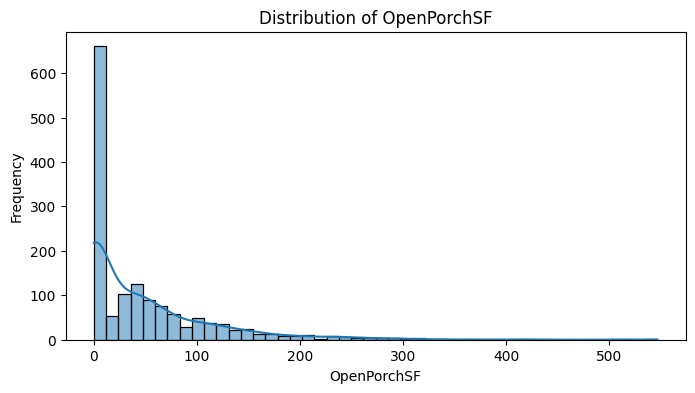

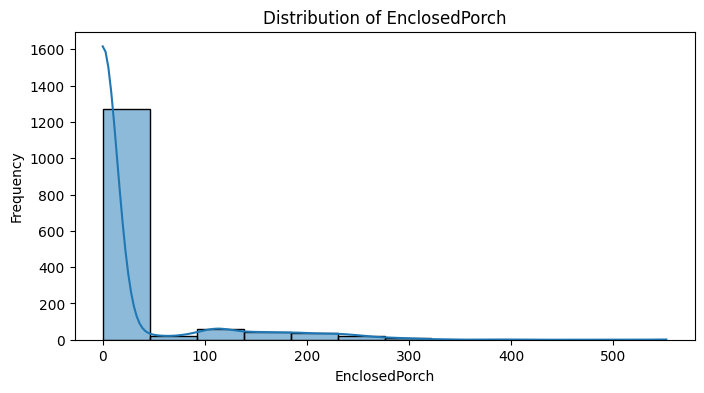

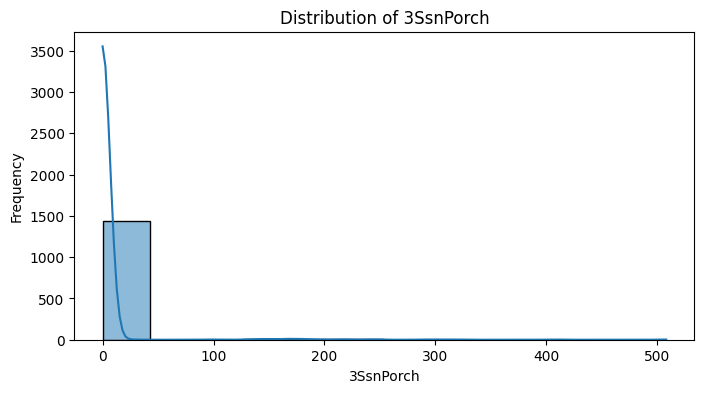

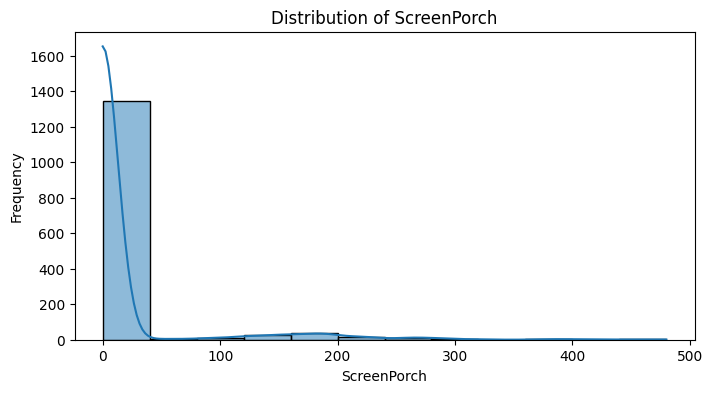

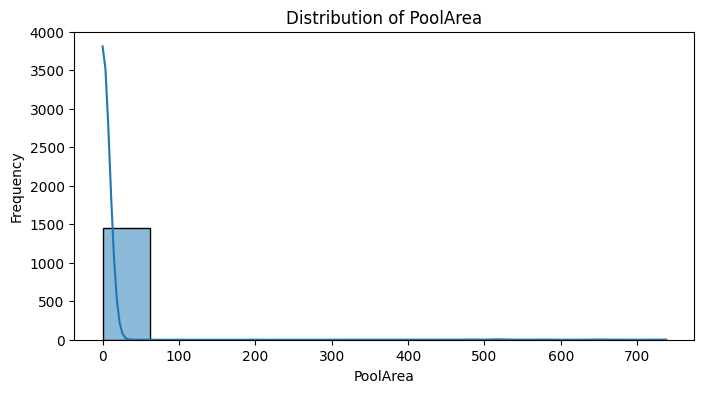

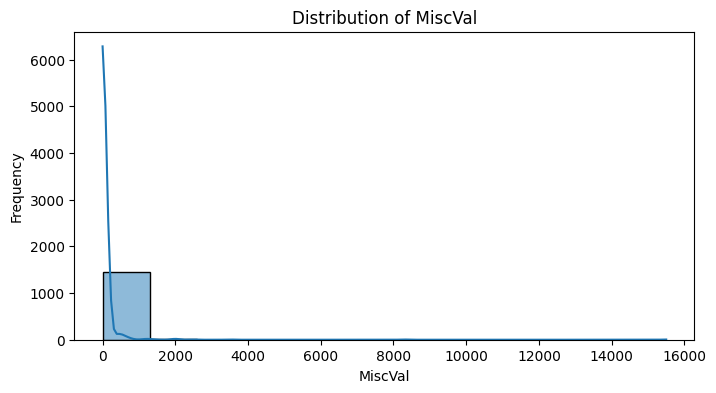

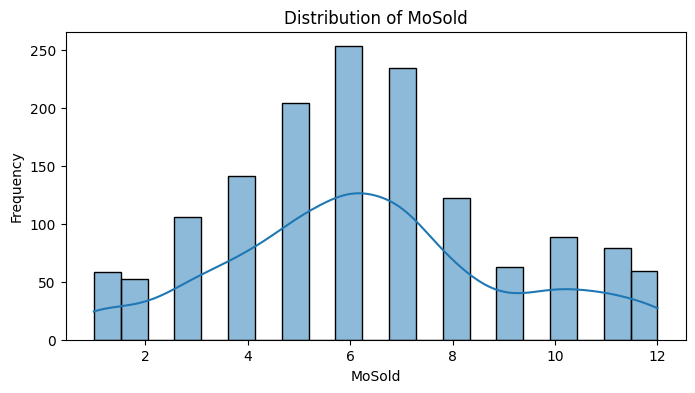

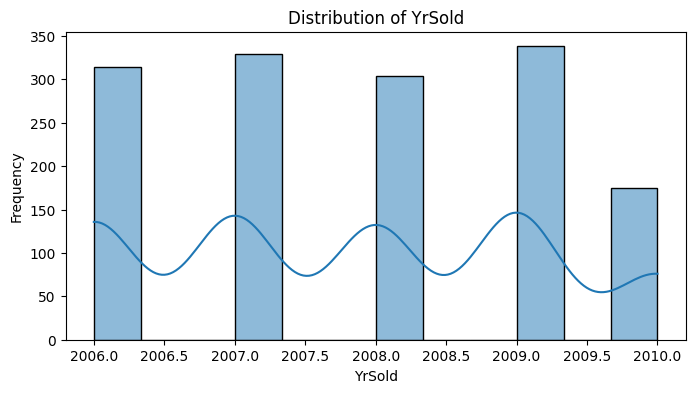

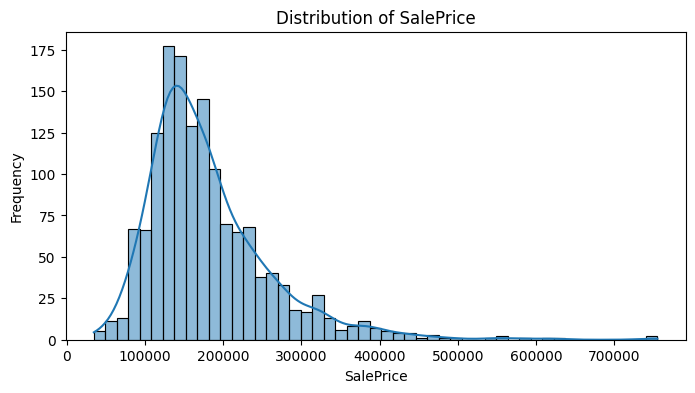

In [22]:
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages("../results/numerical_distributions.pdf") as pdf:

    for col in numeric_features:
        plt.figure(figsize=(8, 4))

        sns.histplot(train_clean[col], kde=True)

        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")

        pdf.savefig()
        plt.show()
        plt.close()

### 9. Correlation Analysis

Εξετάζουμε τις συσχετίσεις μεταξύ των numerical μεταβλητών
χρησιμοποιώντας τον συντελεστή συσχέτισης Pearson.

Η ανάλυση χρησιμοποιείται για τον εντοπισμό χαρακτηριστικών που
παρουσιάζουν πολύ υψηλή συσχέτιση μεταξύ τους και επομένως μπορεί
να περιέχουν παρόμοια πληροφορία.

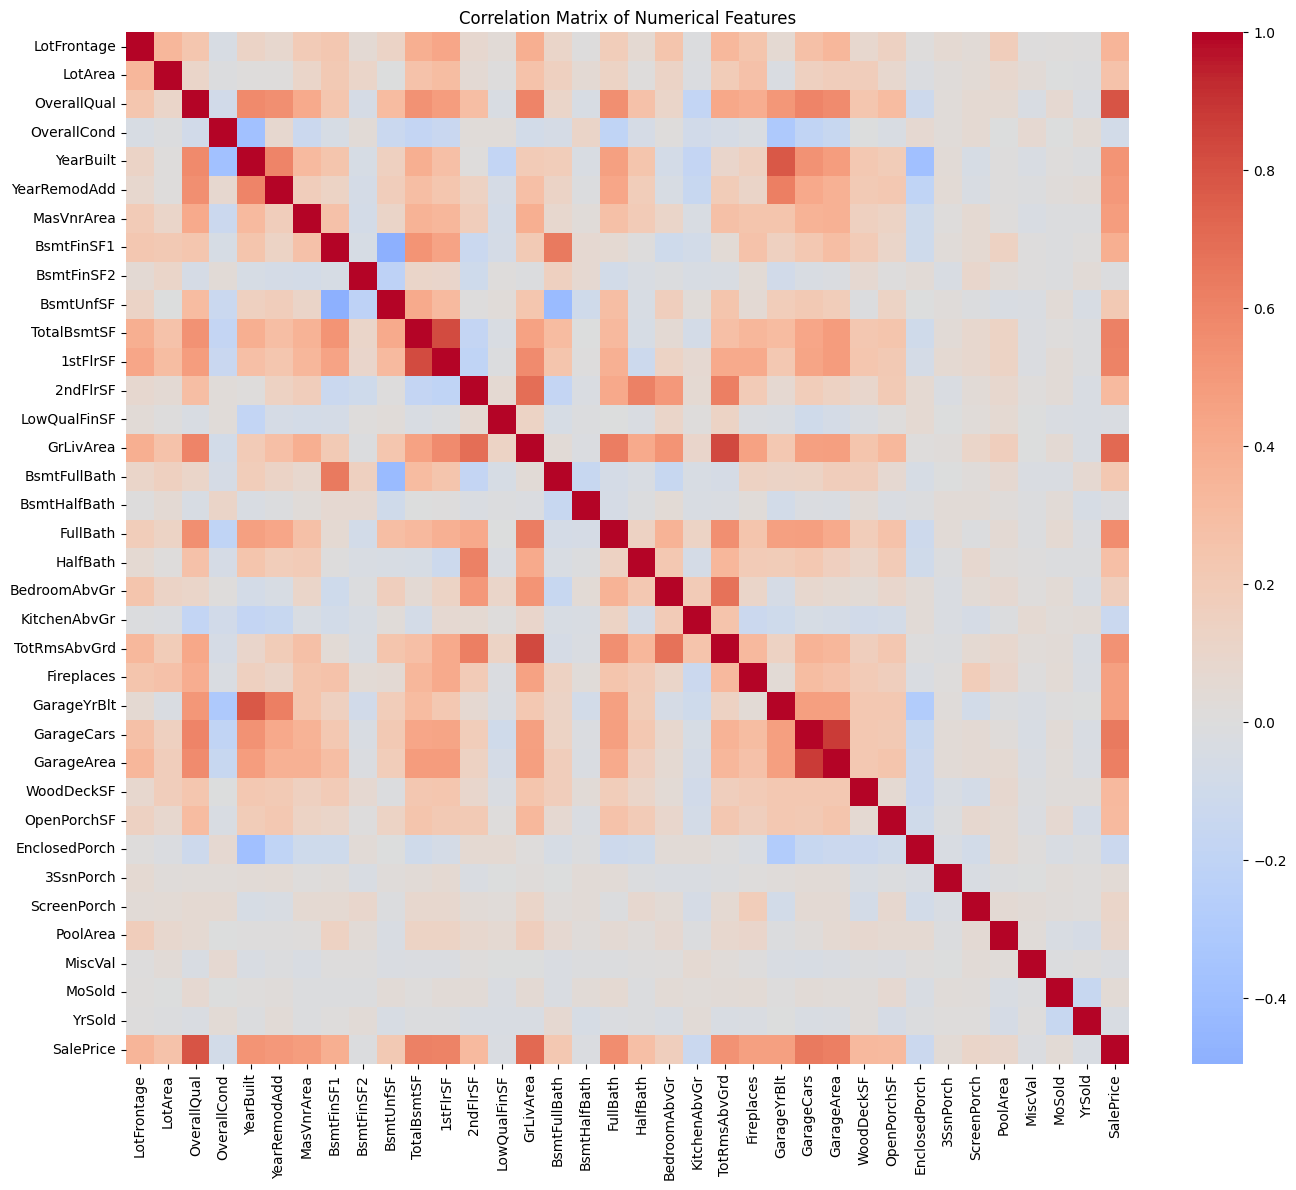

In [23]:
plt.figure(figsize=(14, 12))

correlation_matrix = train_clean[numeric_features].corr() #Υπολογιζουμε τις συσχετισεις μεταξυ των αριθμητικων στηλων
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()

plt.savefig("../results/correlation_heatmap.png", dpi=300)
plt.show()

In [24]:
correlations = correlation_matrix.unstack()

strong_correlations = correlations[
    (abs(correlations) >= 0.70) &
    (correlations != 1)
].sort_values(ascending=False)

strong_correlations

GarageCars    GarageArea      0.882475
GarageArea    GarageCars      0.882475
GrLivArea     TotRmsAbvGrd    0.825489
TotRmsAbvGrd  GrLivArea       0.825489
TotalBsmtSF   1stFlrSF        0.819530
1stFlrSF      TotalBsmtSF     0.819530
OverallQual   SalePrice       0.790982
SalePrice     OverallQual     0.790982
YearBuilt     GarageYrBlt     0.777182
GarageYrBlt   YearBuilt       0.777182
GrLivArea     SalePrice       0.708624
SalePrice     GrLivArea       0.708624
dtype: float64

### 9.1 Highly Correlated Features

Η ανάλυση συσχετίσεων έδειξε τρία ζεύγη numerical χαρακτηριστικών
με υψηλή θετική συσχέτιση:

- GarageCars και GarageArea (r = 0.882)
- GrLivArea και TotRmsAbvGrd (r = 0.825)
- TotalBsmtSF και 1stFlrSF (r = 0.820)

Οι υψηλές συσχετίσεις δείχνουν ότι τα χαρακτηριστικά κάθε ζεύγους περιέχουν σε σημαντικό βαθμό παρόμοια πληροφορία.
Στο παρόν στάδιο διατηρούμε όλα τα χαρακτηριστικά, καθώς περιγράφουν διαφορετικές ιδιότητες των κατοικιών και η υψηλή συσχέτιση δεν σημαίνει ότι παρέχουν ακριβώς την ίδια πληροφορία. Δεν εφαρμόζουμε αφαίρεση χαρακτηριστικών σε αυτό το βήμα.
Το SalePrice διατηρείται στο train ως μεταβλητή-στόχος για την πρόβλεψη της τιμής πώλησης.

### 10. Scaling / Normalization

Οι numerical μεταβλητές έχουν διαφορετικές κλίμακες. Για παράδειγμα,
ορισμένες μεταβλητές έχουν τιμές μερικών μονάδων, ενώ άλλες έχουν
τιμές χιλιάδων.

Για να βρίσκονται οι numerical μεταβλητές σε συγκρίσιμη κλίμακα,
χρησιμοποιούμε StandardScaler.

Το scaling είναι ιδιαίτερα χρήσιμο για αλγορίθμους που επηρεάζονται
από την κλίμακα των χαρακτηριστικών.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()# Δημιουργουμε τον scaler για την τυποποιηση των αριθμητικων χαρακτηριστικων

# Δημιουργουμε αντιγραφα για να διατηρησουμε τα αρχικα δεδομενα
train_scaled = train_clean.copy()
test_scaled = test_clean.copy()

# Εξαιρουμε τη μεταβλητη στοχο SalePrice απο την τυποποιηση
numeric_features_scaling = numeric_features.drop("SalePrice")

# Υπολογιζουμε τη μεση τιμη και την τυπικη αποκλιση στο train και τυποποιουμε
train_scaled[numeric_features_scaling] = scaler.fit_transform(
    train_clean[numeric_features_scaling]
)

# Τυποποιουμε το test με τις παραμετρους που υπολογιστηκαν στο train
test_scaled[numeric_features_scaling] = scaler.transform(
    test_clean[numeric_features_scaling]
)

In [26]:
train_scaled[numeric_features_scaling].describe().T[["mean", "std"]]

,mean,std
LotFrontage,2.920039e-16,1.000343
LotArea,-5.840077e-17,1.000343
OverallQual,1.387018e-16,1.000343
OverallCond,3.540547e-16,1.000343
YearBuilt,1.046347e-15,1.000343
YearRemodAdd,4.496860e-15,1.000343
MasVnrArea,-3.406712e-17,1.000343
BsmtFinSF1,-2.433366e-17,1.000343
BsmtFinSF2,-3.406712e-17,1.000343
BsmtUnfSF,-6.600504e-17,1.000343


### 11. Encoding Categorical Features

Οι categorical μεταβλητές περιέχουν κατηγορίες σε μορφή κειμένου και
πρέπει να μετατραπούν σε αριθμητική μορφή ώστε να μπορούν να
χρησιμοποιηθούν από τους αλγορίθμους μηχανικής μάθησης.

Χρησιμοποιούμε One-Hot Encoding, δημιουργώντας μία binary στήλη
για κάθε κατηγορία.

In [27]:
categorical_features = train_clean.select_dtypes(
    include=["object"]
).columns

categorical_features

Index(['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour',
       'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1',
       'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
       'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond',
       'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
       'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical',
       'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType',
       'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC',
       'Fence', 'MiscFeature', 'SaleType', 'SaleCondition'],
      dtype='object')

### 11.2 One-Hot Encoding
Ορίζουμε τις κατηγορίες από το train και προσθέτουμε την κατηγορία «Unknown» για τιμές που δεν έχουν εμφανιστεί στην εκπαίδευση. Έπειτα μετατρέπουμε τις κατηγορίες σε στήλες 0/1.

In [28]:
train_for_encoding = train_clean.copy()
test_for_encoding = test_clean.copy()

for col in categorical_features:
    categories = sorted(set(train_clean[col]) | {"Unknown"}) #kοινες κατηγοριες με βαση το τρειν

    train_for_encoding[col] = pd.Categorical(
        train_clean[col], categories=categories
    )
    test_values = test_clean[col].where(
        test_clean[col].isin(categories), "Unknown" #μια νεα κατηγορια του τεστ γινεται  unknown
    )
    test_for_encoding[col] = pd.Categorical(
        test_values, categories=categories
    )
train_encoded = pd.get_dummies(
    train_for_encoding,
    columns=categorical_features,
    drop_first=False
)
test_encoded = pd.get_dummies(
    test_for_encoding,
    columns=categorical_features,
    drop_first=False
)

In [29]:
train_encoded, test_encoded = train_encoded.align(
    test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

test_encoded = test_encoded.drop(columns = ["SalePrice"]) #αφαιρω το saleprice απο το test επειδη οι πραγματικες τιμες ειναι αγνωστες

In [30]:
print("Train shape:", train_encoded.shape)
print("Test shape:", test_encoded.shape)

print("\nSame columns:", list(train_encoded.drop(columns=["SalePrice"]).columns) == list(test_encoded.columns))

Train shape: (1460, 362)
Test shape: (1459, 361)

Same columns: True


### 12. Final Preprocessing Validation

Πραγματοποιούμε έναν έλεγχο των επεξεργασμένων δεδομένων για να εντοπίσουμε τυχόν κενές τιμές και να επιβεβαιώσουμε ότι το train και το test έχουν τις ίδιες στήλες χαρακτηριστικών. Το train περιέχει επιπλέον τη μεταβλητή-στόχο SalePrice.

In [31]:
print("Train shape:", train_encoded.shape)
print("Test shape:", test_encoded.shape)

print("\nMissing values in train:", train_encoded.isnull().sum().sum())
print("Missing values in test:", test_encoded.isnull().sum().sum())

print("\nSame columns:", list(train_encoded.drop(columns=["SalePrice"]).columns) == list(test_encoded.columns))

Train shape: (1460, 362)
Test shape: (1459, 361)

Missing values in train: 0
Missing values in test: 0

Same columns: True


### 13. Prepare Output Directory

Δημιουργούμε τον φάκελο αποθήκευσης. Τα τελικά δεδομένα θα αποθηκευτούν αφού ολοκληρωθούν το scaling και οι έλεγχοι της επόμενης ενότητας.

In [32]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)

### 14. Creation of Final Processed Dataset

Δημιουργούμε την τελική έκδοση των δεδομένων συνδυάζοντας:

- τη διαχείριση των missing values,
- το One-Hot Encoding,
- και το scaling των numerical χαρακτηριστικών.

Το `SalePrice` παραμένει μόνο στο training dataset ως target.

In [33]:
# Αντιγράφουμε τα encoded datasets
train_final = train_encoded.copy()
test_final = test_encoded.copy()

# Numerical features που θέλουμε να κάνουμε scale
numeric_features_final = [
    col for col in numeric_features
    if col != "SalePrice"
]

# Κάνουμε scaling μόνο στα numerical features
scaler = StandardScaler()

train_final[numeric_features_final] = scaler.fit_transform(
    train_encoded[numeric_features_final]
)

test_final[numeric_features_final] = scaler.transform(
    test_encoded[numeric_features_final]
)

## 15. Final Validation

Πραγματοποιούμε έναν τελικό έλεγχο των processed datasets.

Ελέγχουμε:

- τις διαστάσεις των train και test datasets,
- ότι δεν υπάρχουν missing values,
- και ότι train και test έχουν ακριβώς τις ίδιες στήλες χαρακτηριστικών, με επιπλέον το `SalePrice` στο train.

In [34]:
print("Train shape:", train_final.shape)
print("Test shape:", test_final.shape)

print("\nMissing values in train:", train_final.isnull().sum().sum())
print("Missing values in test:", test_final.isnull().sum().sum())

print("\nSame columns:", list(train_final.drop(columns=["SalePrice"]).columns) == list(test_final.columns))

Train shape: (1460, 362)
Test shape: (1459, 361)

Missing values in train: 0
Missing values in test: 0

Same columns: True


Αποθηκεύουμε τα τελικά επεξεργασμένα δεδομένα μετά το encoding, το scaling και τον έλεγχο εγκυρότητας. Το train περιλαμβάνει το SalePrice, ενώ το test δεν το περιλαμβάνει.

In [35]:
train_final.to_csv(
    "../data/processed/train_processed.csv",
    index=False
)

test_final.to_csv(
    "../data/processed/test_processed.csv",
    index=False
)

print("Final processed datasets saved successfully.")

Final processed datasets saved successfully.
